<!--
Copyright © 2026 The Trustees of Indiana University and contributors.
This work is licensed under the Creative Commons Attribution-NonCommercial 4.0 International License (CC BY-NC 4.0).
You may use, share, and adapt this work for non-commercial purposes, subject to the terms of the license and appropriate attribution.
See the LICENSE file in the root of this repository for the full license terms.
https://creativecommons.org/licenses/by-nc/4.0/
-->

# Sample Activity Delta Calibration

Loads a sample activity log, computes inter-event deltas,
plots the CCDF(Complementary Cumulative Distribution Function), and fits an exponential model for comparison.


Run simulator (if not done so) 
```bash
cd ../../../libs/simsom
python run_simsom.py
```
Find the latest generated folder
```bash
ls -t files | head -n 1
```


In [ ]:
## Replace the folder name with the above generated folder name
foldername = "1765667098"

import pandas as pd

df = pd.read_csv(f"../../../libs/simsom/files/{foldername}/activities.csv")
df

,message_id,user_id,quality,appeal,reshared_id,reshared_user_id,reshared_original_id,reshared_original_user_id,clock_time
0,P3_u7597,u7597,0.91,0.354767,NaN,NaN,NaN,NaN,142
1,P3_u169,u169,1.00,0.141858,NaN,NaN,NaN,NaN,2462
2,P5_u169,u169,0.54,0.044429,NaN,NaN,NaN,NaN,2596
3,P3_u7930,u7930,1.00,0.360811,NaN,NaN,NaN,NaN,3712
4,P1_u7597,u7597,0.17,0.055442,NaN,NaN,NaN,NaN,4514
...,...,...,...,...,...,...,...,...,...
1008,R0_u3104,u3104,1.00,0.173325,P1_u5836,u5836,P1_u5836,u5836,965958
1009,P3_u3104,u3104,1.00,0.402714,NaN,NaN,NaN,NaN,968801
1010,P0_u3104,u3104,1.00,0.198477,NaN,NaN,NaN,NaN,969691
1011,R0_u5909,u5909,1.00,0.602747,R2_u8351,u8351,P3_u3340,u3340,970095


## Compute Deltas

Convert timestamps to inter-event gaps for distribution analysis.


In [2]:
import numpy as np

timestamps = np.array(df["clock_time"])
deltas = np.diff(timestamps)

## Plot CCDF

Visualize the simulated CCDF of deltas on a log scale.


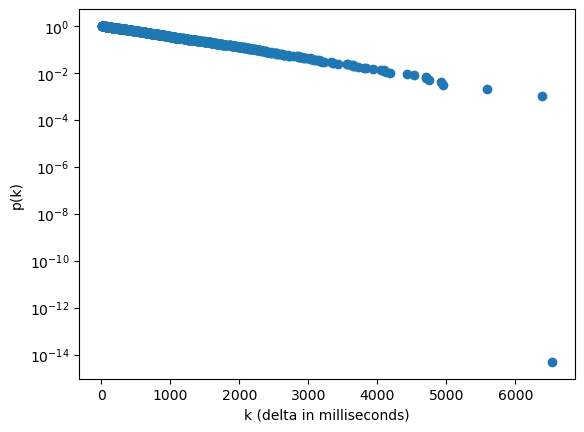

In [3]:
import matplotlib.pyplot as plt
from collections import Counter

counts = Counter(deltas)

X = np.sort(np.array(list(counts.keys())))

max_y = sum(counts.values())
y = [counts[c] / max_y for c in X]

y = 1 - np.cumsum(y)

plt.scatter(X, y)
plt.xlabel("k (delta in milliseconds)")
plt.ylabel("p(k)")
plt.yscale("log")
plt.show()

## Fit Exponential Model

Fit an exponential curve to compare with the simulated CCDF.


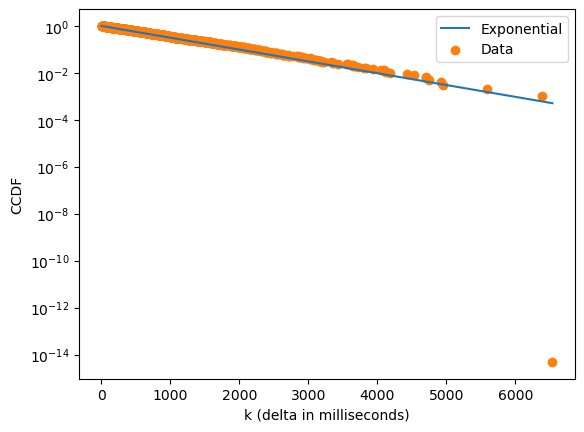

In [4]:
from scipy.optimize import curve_fit

def exp_log(x, b):
    return -b * x

def exp(x, b):
    return np.exp(-b * x)

popt, pcov = curve_fit(exp_log, X, np.log(y), maxfev=2000)

linspace = np.linspace(1, max(X))
plt.plot(linspace, exp(linspace, *popt), label="Exponential", color=plt.cm.tab10(0))
plt.scatter(X, y, label="Data", color=plt.cm.tab10(1))
plt.xlabel("k (delta in milliseconds)")
plt.ylabel("CCDF")
plt.legend()
plt.yscale("log")
plt.show()